# Insurer or Plan? Milestone 2 analysis
**ANLY 530 · KA1 Milestone 2** · Ankit Bisht

Research question (unchanged from Milestone 1): how much of the variation in claim denial rates across ACA Marketplace plans is attributable to the insurer rather than to the plan's design, and can publicly reported plan attributes predict a plan's denial rate for insurers not seen during training?

This notebook reproduces every number, table and figure in the Milestone 2 progress report. It adds the checks requested in the Milestone 1 reviews.

| Requested check | Section |
|---|---|
| Selection bias from excluded plans | 2 |
| Sensitivity to insurer concentration and to claim-volume weighting | 3 and 4 |
| Paired model-baseline comparisons with uncertainty | 4 |
| Insurers absent from training versus insurers new to the Marketplace | 5 |

Data: CMS Transparency in Coverage Public Use Files for plan years 2024, 2025 and 2026, which report claims for calendar years 2022, 2023 and 2024. The files are downloaded from CMS on first run and cached in `data/`. Run all cells from top to bottom. The run takes about 10 minutes and uses all CPU cores. Seed: 42.

## 1. Data preparation

In [1]:
import io, zipfile, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from joblib import Parallel, delayed

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, GroupKFold, GridSearchCV

warnings.simplefilter("ignore")      # statsmodels boundary notices; variance components are printed and checked below
SEED = 42
REPEATS = 10                         # repeats of the 5-fold insurer-grouped split
DATA, FIG = Path("data"), Path("figures")
DATA.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)

REC, DEN = "Plan_Number_Claims_Received_In_Network", "Plan_Number_Claims_Denied_In_Network"
IREC, IDEN = "Issuer_Claims_Received_In_Network", "Issuer_Claims_Denied_In_Network"
NEW = "Is_Issuer_New_to_Exchange?(Yes_or_No)"
CAT = ["Plan_Type", "Metal_Level", "Exchange_Type"]

def load_puf(file_year):
    """CMS Transparency in Coverage PUF. The file for plan year Y reports claims for calendar year Y - 2."""
    local = DATA / f"transparency_in_coverage_puf_{file_year}.xlsx"
    if not local.exists():
        url = f"https://download.cms.gov/marketplace-puf/{file_year}/transparency-in-coverage-puf.zip"
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
        local.write_bytes(z.read([n for n in z.namelist() if n.lower().endswith(".xlsx")][0]))
    # Column names are on the third row; keep_default_na=False keeps CMS codes such as "N/A" visible
    return pd.read_excel(local, sheet_name=f"Transparency {file_year} - Ind QHP", header=2, keep_default_na=False)

raw, use = {}, {}
for fy in (2024, 2025, 2026):
    cy = fy - 2                                                   # claims year
    r = load_puf(fy)
    for c in (REC, DEN, IREC, IDEN):
        r[c + "_num"] = pd.to_numeric(r[c], errors="coerce")      # CMS codes ("N/A", "**") become missing
    r["iss"] = r["Issuer_ID"].astype(str)
    r["usable"] = (r[REC + "_num"] > 0) & r[DEN + "_num"].notna()  # the target can be computed
    r["rate"] = (r[DEN + "_num"] / r[REC + "_num"]).where(r["usable"])
    r["claims"] = r[REC + "_num"]
    enroll_col = "Average Monthly Enrollment" if "Average Monthly Enrollment" in r.columns else "Enrollment_Data"   # renamed after the 2024 file
    r["enrollment"] = pd.to_numeric(r[enroll_col], errors="coerce")
    raw[cy] = r
# The 2024 file (claims year 2022) has no Exchange_Type column. Exchange type is fixed within a state, so it is filled from the 2025 file.
state_type = raw[2023].groupby("State")["Exchange_Type"].first()
assert raw[2023].groupby("State")["Exchange_Type"].nunique().max() == 1 and raw[2024].groupby("State")["Exchange_Type"].nunique().max() == 1
raw[2022]["Exchange_Type"] = raw[2022]["State"].map(state_type).fillna("not listed")

def insurer_rate(cy):
    """Insurer-level in-network denial rate reported in the file for claims year cy."""
    p = raw[cy].drop_duplicates("iss")
    p = p[p[IREC + "_num"] > 0]
    return (p[IDEN + "_num"] / p[IREC + "_num"]).set_axis(p["iss"])

for cy, r in raw.items():
    r["prior_issuer_rate"] = r["iss"].map(insurer_rate(cy - 1)) if cy - 1 in raw else np.nan   # public before the year starts
    use[cy] = r[r["usable"]].reset_index(drop=True)
d = use[2024]
print({cy: f"{len(r)} plans in file, {len(use[cy])} usable, {use[cy]['iss'].nunique()} insurers with usable plans" for cy, r in raw.items()})

{2022: '5050 plans in file, 1755 usable, 169 insurers with usable plans', 2023: '4541 plans in file, 2406 usable, 174 insurers with usable plans', 2024: '4159 plans in file, 2527 usable, 149 insurers with usable plans'}


In [2]:
rows = []
for cy, r in raw.items():
    g = r.groupby("iss").agg(usable=("usable", "sum"), new=(NEW, "first"), flags=(NEW, "nunique"))
    assert (g["flags"] == 1).all()                                # the new-insurer flag is constant within an insurer
    rows.append({"claims year": cy, "plans in file": len(r), "usable plans": int(r["usable"].sum()), "usable share": r["usable"].mean(),
                 "coded N/A": int((r[REC] == "N/A").sum()), "suppressed (**)": int(((r[REC] == "**") | (r[DEN] == "**")).sum()),
                 "insurers in file": len(g), "insurers with usable plans": int((g["usable"] > 0).sum()),
                 "insurers flagged new to the Exchange": int((g["new"] == "Yes").sum()),
                 "plans of flagged-new insurers": int((r[NEW] == "Yes").sum()),
                 "usable plans of flagged-new insurers": int(((r[NEW] == "Yes") & r["usable"]).sum()),
                 "median plan denial rate": r["rate"].median()})
table1 = pd.DataFrame(rows).set_index("claims year")
print(table1.round(3).T.to_string())

print()
print("Data-quality checks on the 2024 usable plans")
print("  enrollment missing or suppressed:", round(d["enrollment"].isna().mean(), 3))
print("  median claims received per average monthly enrollee:", round((d.loc[d["enrollment"] > 0, "claims"] / d.loc[d["enrollment"] > 0, "enrollment"]).median()))
reason_cols = [c for c in raw[2024].columns if c.startswith("Plan_Number_Claims_Denied_") and "Network" not in c and not c.endswith("_num")]
reasons = sum(pd.to_numeric(raw[2024][c], errors="coerce").sum() for c in reason_cols)
print(f"  denials summed over the {len(reason_cols)} reason columns: {reasons:,.0f} | in-network denials: {d[DEN + '_num'].sum():,.0f}")
print("  plans with a denial rate of exactly 0 or above 0.6:", int((d["rate"] == 0).sum()), "and", int((d["rate"] > 0.6).sum()))

# Is the enrollment field comparable between files? Compare the same plans in consecutive years.
print()
for a, b in ((2022, 2023), (2023, 2024)):
    m = use[a][["Plan_ID", "enrollment", "claims"]].merge(use[b][["Plan_ID", "enrollment", "claims"]], on="Plan_ID", suffixes=("_a", "_b"))
    m = m[(m["enrollment_a"] > 0) & (m["enrollment_b"] > 0)]
    print(f"Same plans, {a} to {b} ({len(m)} plans): median enrollment ratio {(m['enrollment_b'] / m['enrollment_a']).median():.2f}, "
          f"median claims ratio {(m['claims_b'] / m['claims_a']).median():.2f}")
print("Median claims received per enrollee by claims year:",
      {cy: round((u.loc[u["enrollment"] > 0, "claims"] / u.loc[u["enrollment"] > 0, "enrollment"]).median()) for cy, u in use.items()})

claims year                               2022     2023      2024
plans in file                         5050.000  4541.00  4159.000
usable plans                          1755.000  2406.00  2527.000
usable share                             0.348     0.53     0.608
coded N/A                             3092.000  2060.00  1600.000
suppressed (**)                        200.000    45.00    21.000
insurers in file                       209.000   206.00   185.000
insurers with usable plans             169.000   174.00   149.000
insurers flagged new to the Exchange    35.000    29.00    26.000
plans of flagged-new insurers          396.000   371.00   352.000
usable plans of flagged-new insurers     0.000     0.00     0.000
median plan denial rate                  0.149     0.18     0.176

Data-quality checks on the 2024 usable plans
  enrollment missing or suppressed: 0.231
  median claims received per average monthly enrollee: 453
  denials summed over the 9 reason columns: 78,605,749 | in-n

**What the preparation shows.**

- **Target and usable plans.** One row is one individual-market plan. The target is the in-network denial rate (claims denied / claims received). It can be computed when claims received is positive and denials are reported: 2,527 of 4,159 plans in the 2024 claims year (60.8%), up from 34.8% in 2022 and 53.0% in 2023. CMS codes such as "N/A" and "**" are read as missing, never as zero.
- **Schema changes.** The oldest file has no `Exchange_Type` column and calls enrollment `Enrollment_Data`. Exchange type is the same for every plan in a state, so it is filled from the state.
- **Enrollment is not comparable across files.** For the same plans, enrollment in the 2024 claims year is a median 0.12 of its 2023 value, while claims received rose by a factor of 1.34. Claims per enrollee jump from 43 to 453. Between 2022 and 2023 the two moved together (0.98 and 1.06). Enrollment is therefore used only within a year and is left out of any model trained on one year and applied to the next.
- **New insurers.** CMS flags 26 insurers (352 plans) as new to the Exchange in the 2024 file. In none of the three years does a flagged insurer have a usable plan. Section 5 uses this flag.
- **Checks carried over from Milestone 1.** Enrollment is missing for 23.1% of usable 2024 plans. The nine denial-reason columns sum to 78.6 million, more than the 65.6 million in-network denials, so reasons are not used. Two plans report a rate of exactly 0 and three a rate above 0.6; they are kept.

## 2. Are the excluded plans different?

The target cannot be computed for 1,632 of the 4,159 plans in the 2024 claims year. If those plans differ from the usable ones, the results describe only part of the market.

In [3]:
r = raw[2024]
ins = r.groupby("iss").agg(usable=("usable", "sum"), new=(NEW, "first"))
r["kind"] = np.where(r["usable"], "usable",
            np.where(r[NEW] == "Yes", "excluded: insurer flagged new to the Exchange",
            np.where(r["iss"].map(ins["usable"]) > 0, "excluded: established insurer that has other usable plans",
                     "excluded: established insurer with no usable plan")))
kinds = r.groupby("kind").agg(plans=("iss", "size"), insurers=("iss", "nunique"))
kinds["share of excluded plans"] = np.where(kinds.index == "usable", np.nan, kinds["plans"] / (~r["usable"]).sum())
print(kinds.round(3).to_string())

print()
print("Mix of plan attributes, excluded against usable plans (2024)")
for c in CAT:
    t = pd.crosstab(r[c], r["usable"].map({True: "usable", False: "excluded"}), normalize="columns")
    p = stats.chi2_contingency(pd.crosstab(r[c], r["usable"]))[1]
    print(f"--- {c} (chi-square p = {p:.2g})"); print(t.round(3).to_string())

                                                           plans  insurers  share of excluded plans
kind                                                                                               
excluded: established insurer that has other usable plans   1107       121                    0.678
excluded: established insurer with no usable plan            173        10                    0.106
excluded: insurer flagged new to the Exchange                352        26                    0.216
usable                                                      2527       149                      NaN

Mix of plan attributes, excluded against usable plans (2024)


--- Plan_Type (chi-square p = 3.2e-36)
usable     excluded  usable
Plan_Type                  
EPO           0.272   0.262
HMO           0.621   0.473
POS           0.044   0.137
PPO           0.064   0.128
--- Metal_Level (chi-square p = 1.2e-05)
usable        excluded  usable
Metal_Level                   
Bronze           0.298   0.325
Catastrophic     0.015   0.030
Gold             0.271   0.300
Platinum         0.010   0.011
Silver           0.405   0.334
--- Exchange_Type (chi-square p = 0.00017)
usable         excluded  usable
Exchange_Type                  
FFE               0.685   0.743
SBE-FP            0.028   0.026
SPE               0.287   0.231


In [4]:
# Later-observed test. A plan excluded in year t (coded N/A or suppressed) often reports in year t + 1.
# If excluded plans were systematically different, these newly reporting plans should differ from plans that reported in both years.
def later_observed(a, b):
    prev = raw[a][["Plan_ID", "usable"]].rename(columns={"usable": "usable_prev"})
    cur = use[b][["Plan_ID", "rate", "iss"]].merge(prev, on="Plan_ID", how="left")
    cur = cur[cur["usable_prev"].notna()].copy()                       # plan listed in both files
    cur["newly"] = (cur["usable_prev"] == False).astype(int)           # 1 = excluded in year a, usable in year b
    diff = cur.loc[cur.newly == 1, "rate"].mean() - cur.loc[cur.newly == 0, "rate"].mean()
    rng = np.random.default_rng(SEED); ids = cur["iss"].unique(); by = {s: g for s, g in cur.groupby("iss")}; bs = []
    for _ in range(1000):                                              # cluster bootstrap over insurers
        bd = pd.concat([by[s] for s in rng.choice(ids, len(ids), replace=True)])
        if bd["newly"].nunique() == 2:
            bs.append(bd.loc[bd.newly == 1, "rate"].mean() - bd.loc[bd.newly == 0, "rate"].mean())
    both = cur.groupby("iss")["newly"].nunique(); mixed = cur[cur["iss"].isin(both[both == 2].index)]
    fe = smf.ols("rate ~ newly + C(iss)", mixed).fit(cov_type="cluster", cov_kwds={"groups": mixed["iss"]})
    return {"year pair": f"{a} to {b}", "newly reporting plans": int(cur.newly.sum()), "plans usable in both years": int((cur.newly == 0).sum()),
            "mean rate, newly reporting": cur.loc[cur.newly == 1, "rate"].mean(), "mean rate, both years": cur.loc[cur.newly == 0, "rate"].mean(),
            "difference": diff, "95% low": np.percentile(bs, 2.5), "95% high": np.percentile(bs, 97.5),
            "insurers with both kinds": mixed["iss"].nunique(), "difference within insurer": fe.params["newly"],
            "within 95% low": fe.conf_int().loc["newly", 0], "within 95% high": fe.conf_int().loc["newly", 1]}
later = pd.DataFrame([later_observed(2022, 2023), later_observed(2023, 2024)]).set_index("year pair")
print(later.round(4).T.to_string())

# Reweighting: give each usable plan the weight 1 / P(usable | plan type, metal level, exchange type),
# so that the usable plans have the same mix of observed attributes as the full 2024 file.
r = raw[2024]
Xp = pd.get_dummies(r[CAT]).astype(float)
ps = LogisticRegression(max_iter=2000, C=1e6).fit(Xp, r["usable"]).predict_proba(Xp)[:, 1]
ipw = (1 / ps)[r["usable"].values]
print()
print(f"Inverse-probability weights: probability of being usable from {ps.min():.3f} to {ps.max():.3f}; largest weight {ipw.max():.2f}")
print(f"Mean plan denial rate: unweighted {d['rate'].mean():.4f} | reweighted to the full file's plan mix {np.average(d['rate'], weights=ipw):.4f}")

year pair                   2022 to 2023  2023 to 2024
newly reporting plans          1338.0000      781.0000
plans usable in both years     1063.0000     1744.0000
mean rate, newly reporting        0.1999        0.1726
mean rate, both years             0.1717        0.1810
difference                        0.0282       -0.0084
95% low                           0.0100       -0.0184
95% high                          0.0415        0.0125
insurers with both kinds        138.0000       88.0000
difference within insurer         0.0131       -0.0090
within 95% low                    0.0029       -0.0190
within 95% high                   0.0233        0.0010

Inverse-probability weights: probability of being usable from 0.436 to 0.876; largest weight 2.29
Mean plan denial rate: unweighted 0.1784 | reweighted to the full file's plan mix 0.1806


**What the selection checks show.**

- **Who is excluded.** 1,107 excluded plans (67.8%) belong to an established insurer that also has usable plans, 173 (10.6%) to 10 established insurers with no usable plan, and 352 (21.6%) to the 26 insurers flagged new.
- **The mix differs.** 62.1% of excluded plans are HMOs against 47.3% of usable plans, and 40.5% are Silver against 33.4%. The differences in plan type, metal level and exchange type are all statistically clear (chi-square p below 0.001).
- **Later-observed test.** Many excluded plans report a year later, which shows what their rates turn out to be. Plans that began reporting in 2023 had rates 2.82 points higher than plans that reported in both years (95% interval 1.00 to 4.15). Plans that began reporting in 2024 were 0.84 points lower (interval -1.84 to +1.25). Compared only with other plans of the same insurer, the gaps are +1.31 points (0.29 to 2.33) and -0.90 points (-1.90 to +0.10). Newly reporting plans are not consistently higher or lower.
- **Reweighting.** Giving the usable plans the plan mix of the whole file moves the mean rate from 17.8% to 18.1% and leaves the insurer share of variance unchanged (Section 3).

These checks have limits. Reweighting adjusts only for attributes that are recorded, and the later-observed test covers only plans that eventually report. Insurers that are new to the Exchange are examined in Section 5.

## 3. How much of the variation belongs to the insurer?

This is the primary analysis. A random-intercept model (plans within insurers, fitted by REML) gives the insurer share of variance, the intraclass correlation (ICC). Eta-squared, the between-insurer share of the sum of squares, is a model-free check that also allows weights. The same estimate is then recomputed under each check requested in the reviews.

2024, all usable plans: insurer ICC 0.612 | insurer SD 0.0600 | plan (residual) SD 0.0478


95% cluster-bootstrap interval (200 resamples of insurers): 0.446 to 0.736


After adding plan type, metal level and exchange type: ICC 0.611; share of insurer variance they explain 0.037
  Plan_Type within insurer: 0.006 of total variance
  Metal_Level within insurer: 0.004 of total variance


Three-level model: state 0.203, insurer within state 0.417, plan 0.379
Claims received per plan: 5th percentile 706, median 24,033, 95th percentile 543,380; plans under 1,000 claims 0.067
Average binomial sampling variance 0.000054 against plan-level (within-insurer) variance 0.002281: 0.024 of it



                                                         plans  insurers  ICC (REML)  eta-squared
check                                                                                            
2024, all usable plans                                    2527       149       0.612        0.545
Without the largest insurer (522 plans, 20.7%)            2005       148       0.588        0.569
Plans with at least 1,000 claims                          2357       147       0.619        0.559
Plans with at least 10,000 claims                         1668       137       0.649        0.582
Weighted by claims received                               2527       149         NaN        0.571
Reweighted to the full file's plan mix                    2527       149         NaN        0.545
Established insurers only (first-year insurers removed)   2472       141       0.606        0.539
2023, all usable plans                                    2406       174       0.698        0.655
2022, all usable pl

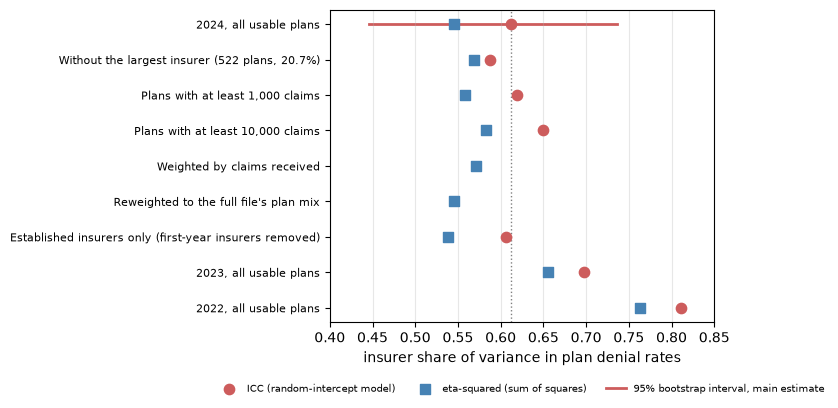

In [5]:
def icc(df, formula="rate ~ 1"):
    """Insurer share of variance from a random-intercept model fitted by REML."""
    m = smf.mixedlm(formula, df, groups=df["iss"]).fit(reml=True)
    v = m.cov_re.iloc[0, 0]
    return v / (v + m.scale), v, m.scale

def eta2(y, g, w=None):
    """Between-insurer share of the (optionally weighted) sum of squares."""
    y = np.asarray(y, float); w = np.ones(len(y)) if w is None else np.asarray(w, float)
    mu = np.average(y, weights=w)
    gm = pd.DataFrame({"yw": y * w, "w": w, "g": np.asarray(g)}).groupby("g").sum()
    m = (gm["yw"] / gm["w"]).reindex(np.asarray(g)).values
    return (w * (m - mu) ** 2).sum() / (w * (y - mu) ** 2).sum()

main_icc, v_ins, v_res = icc(d)
print(f"2024, all usable plans: insurer ICC {main_icc:.3f} | insurer SD {np.sqrt(v_ins):.4f} | plan (residual) SD {np.sqrt(v_res):.4f}")

# Cluster bootstrap over insurers for the main estimate
rng = np.random.default_rng(SEED); insurers = d["iss"].unique(); by = {s: g for s, g in d.groupby("iss")}; boot = []
for b in range(200):
    pick = rng.choice(insurers, len(insurers), replace=True)
    bd = pd.concat([by[s].assign(iss=f"{s}_{j}") for j, s in enumerate(pick)])
    boot.append(icc(bd)[0])
ci = np.percentile(boot, [2.5, 97.5])
print(f"95% cluster-bootstrap interval (200 resamples of insurers): {ci[0]:.3f} to {ci[1]:.3f}")

# How much of the insurer variance do plan attributes account for?
attrs = 'rate ~ C(Plan_Type, Treatment("HMO")) + C(Metal_Level, Treatment("Silver")) + C(Exchange_Type)'
icc_attr, v_ins_attr, _ = icc(d, attrs)
print(f"After adding plan type, metal level and exchange type: ICC {icc_attr:.3f}; share of insurer variance they explain {1 - v_ins_attr / v_ins:.3f}")
within = d["rate"] - d.groupby("iss")["rate"].transform("mean"); sst = ((d["rate"] - d["rate"].mean()) ** 2).sum()
for c in ("Plan_Type", "Metal_Level"):
    print(f"  {c} within insurer: {eta2(within, d[c]) * (within ** 2).sum() / sst:.3f} of total variance")

# Is it the insurer or the state? Three-level model: plans within insurers within states
three = smf.mixedlm("rate ~ 1", d, groups=d["State"], re_formula="1", vc_formula={"iss": "0 + C(iss)"}).fit(reml=True)
vs, vi, ve = three.cov_re.iloc[0, 0], three.vcomp[0], three.scale
print(f"Three-level model: state {vs / (vs + vi + ve):.3f}, insurer within state {vi / (vs + vi + ve):.3f}, plan {ve / (vs + vi + ve):.3f}")

# Sampling noise: a rate from n claims has binomial variance p(1 - p) / n
binom = d["rate"] * (1 - d["rate"]) / d["claims"]
print(f"Claims received per plan: 5th percentile {d['claims'].quantile(0.05):,.0f}, median {d['claims'].median():,.0f}, 95th percentile {d['claims'].quantile(0.95):,.0f}; "
      f"plans under 1,000 claims {(d['claims'] < 1000).mean():.3f}")
print(f"Average binomial sampling variance {binom.mean():.6f} against plan-level (within-insurer) variance {v_res:.6f}: {binom.mean() / v_res:.3f} of it")

# The same estimate under each sensitivity check
vc = d["iss"].value_counts(); top = vc.index[0]
flag_prev = raw[2023].groupby("iss")[NEW].first()
first_2024 = [s for s in d["iss"].unique() if flag_prev.get(s) == "Yes"]          # insurers in their first claims year
checks = [("2024, all usable plans", d, None)]
checks.append((f"Without the largest insurer ({vc.iloc[0]} plans, {vc.iloc[0] / len(d):.1%})", d[d.iss != top], None))
checks += [(f"Plans with at least {cut:,} claims", d[d["claims"] >= cut], None) for cut in (1000, 10000)]
checks.append(("Weighted by claims received", d, d["claims"].values))
checks.append(("Reweighted to the full file's plan mix", d, ipw))
checks.append(("Established insurers only (first-year insurers removed)", d[~d["iss"].isin(first_2024)], None))
checks += [(f"{cy}, all usable plans", use[cy], None) for cy in (2023, 2022)]
rows = []
for label, df, w in checks:
    rows.append({"check": label, "plans": len(df), "insurers": df["iss"].nunique(),
                 "ICC (REML)": np.nan if w is not None else icc(df)[0], "eta-squared": eta2(df["rate"], df["iss"], w)})
table2 = pd.DataFrame(rows).set_index("check")
loo = [icc(d[d.iss != s])[0] for s in vc.index[:5]]
print()
print(table2.round(3).to_string())
print(f"Leaving out each of the five largest insurers in turn (their plan shares: {', '.join(f'{x:.1%}' for x in vc.head(5) / len(d))}): ICC from {min(loo):.3f} to {max(loo):.3f}")
print(f"Largest insurer: mean plan rate {d.loc[d.iss == top, 'rate'].mean():.4f} against {d.loc[d.iss != top, 'rate'].mean():.4f} for all other plans")
print(f"Claim-weighted mean plan rate {np.average(d['rate'], weights=d['claims']):.4f} against unweighted {d['rate'].mean():.4f}")
print(f"Across all rows: ICC from {table2['ICC (REML)'].min():.3f} to {table2['ICC (REML)'].max():.3f}; eta-squared from {table2['eta-squared'].min():.3f} to {table2['eta-squared'].max():.3f}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
lab = list(table2.index)
for i, k in enumerate(lab):
    a, e = table2.loc[k, "ICC (REML)"], table2.loc[k, "eta-squared"]
    if not np.isnan(a):
        ax.scatter(a, i, color="indianred", s=55, zorder=3, label="ICC (random-intercept model)" if i == 0 else None)
    ax.scatter(e, i, color="steelblue", s=45, marker="s", zorder=2, label="eta-squared (sum of squares)" if i == 0 else None)
ax.plot(ci, [0, 0], color="indianred", lw=2, zorder=1, label="95% bootstrap interval, main estimate")
ax.axvline(main_icc, color="grey", ls=":", lw=1)
ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab, fontsize=8); ax.invert_yaxis(); ax.set_xlim(0.4, 0.85)
ax.set_xlabel("insurer share of variance in plan denial rates"); ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "m2_fig1_insurer_share.png", dpi=200, bbox_inches="tight"); plt.show()

**What the decomposition shows.** In 2024, 61.2% of the variance in plan denial rates lies between insurers (95% cluster-bootstrap interval 44.6% to 73.6%). The insurer standard deviation is 6.0 points; the standard deviation of plans within an insurer is 4.8 points. Plan type, metal level and exchange type together explain 3.7% of the insurer variance, and within an insurer plan type accounts for 0.6% of total variance and metal level for 0.4%. A three-level model puts 20.3% at the state, 41.7% at the insurer within state and 37.9% at the plan, so the insurer effect is not only geography.

The estimate holds under each check:

- **Insurer concentration.** Without the largest insurer (522 plans, 20.7% of usable plans) the ICC is 0.588. Leaving out each of the five largest insurers in turn gives 0.588 to 0.632.
- **Claim volume.** Sampling noise is small: the binomial variance of a plan's rate averages 2.4% of the plan-level variance. Keeping only plans with at least 1,000 claims gives 0.619, and at least 10,000 claims 0.649. Weighting each plan by its claims gives an eta-squared of 0.571 against 0.545 unweighted.
- **Selection.** Reweighting to the full file's plan mix leaves eta-squared at 0.545. Removing the eight insurers in their first claims year gives an ICC of 0.606.
- **Other years.** The ICC is 0.698 in 2023 and 0.811 in 2022, so 2024 is the lowest of the three years. The 2022 figure rests on only 34.8% of that file.

Across all rows the ICC runs from 0.588 to 0.811 and eta-squared from 0.539 to 0.763. Every check leaves more than half of the variation with the insurer.

## 4. Can a model predict denial rates for insurers it has not seen?

Changes from Milestone 1:

- Every model is tuned inside the training fold, on inner folds grouped by insurer. In Milestone 1 only ridge was tuned.
- A random forest is added, as planned in the protocol.
- The insurer-grouped 5-fold split is repeated 10 times, giving 50 test folds.
- Each model is compared with the baseline fold by fold. The 95% interval for the difference uses the corrected resampled t-test (Nadeau & Bengio, 2003), which widens the interval to allow for the overlap between training sets.
- The comparison is repeated with plans weighted by claims received and with the largest insurer removed.

The metric is mean absolute error (MAE) in denial-rate units: 0.01 is one percentage point.

In [6]:
BASE = "Baseline: training-fold mean"
FEATURES = CAT + ["State", "enrollment", "prior_issuer_rate"]
log_enroll = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), FunctionTransformer(np.log1p), StandardScaler())

def design(cat, extra=(), enroll=True):
    """One-hot categories, log enrollment with a missing-value indicator, optional extra numeric columns. Fitted on training rows only."""
    parts = [("cat", OneHotEncoder(handle_unknown="ignore"), cat)]
    if enroll:
        parts.append(("enroll", log_enroll, ["enrollment"]))
    if extra:
        parts.append(("extra", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), list(extra)))
    return ColumnTransformer(parts)

def tuned(prep, estimator, grid, inner):
    return GridSearchCV(Pipeline([("prep", prep), ("m", estimator)]), grid, cv=inner, scoring="neg_mean_absolute_error")

def make_models(inner, cross_year=False):
    """Every model is tuned inside the training data, on inner folds of the same kind as the outer folds.
    cross_year=True is for training on one year and predicting the next: no prior-year rate (new insurers have none)
    and no enrollment (its scale differs between files)."""
    alphas = {"m__alpha": [0.1, 1, 10, 100, 1000]}
    extra, enroll = ([], False) if cross_year else (["prior_issuer_rate"], True)
    label = "plan attributes + state" if cross_year else "all public predictors"
    models = {"Ridge: plan attributes": tuned(design(CAT, enroll=enroll), Ridge(), alphas, inner),
              "Ridge: plan attributes + state": tuned(design(CAT + ["State"], enroll=enroll), Ridge(), alphas, inner)}
    if not cross_year:
        models["Ridge: plan attributes + prior-year insurer rate"] = tuned(design(CAT, extra), Ridge(), alphas, inner)
    models[f"Random forest: {label}"] = tuned(design(CAT + ["State"], extra, enroll), RandomForestRegressor(n_estimators=200, random_state=SEED),
                                              {"m__min_samples_leaf": [5, 25, 100]}, inner)
    models[f"Gradient boosting: {label}"] = tuned(design(CAT + ["State"], extra, enroll), GradientBoostingRegressor(random_state=SEED),
                                                  {"m__n_estimators": [30, 100, 300]}, inner)
    return models

def fold_errors(df, tr, te, inner, weights=None):
    """Mean absolute error of the baseline and of every model on one test fold.
    With weights, the baseline, the model fits and the test error are all weighted by claims; the inner tuning score is not."""
    X, y, g = df[FEATURES], df["rate"].values, df["iss"].values
    w_tr, w_te = (None, None) if weights is None else (weights[tr], weights[te])
    out = {"n_train": len(tr), "n_test": len(te), BASE: np.average(np.abs(y[te] - np.average(y[tr], weights=w_tr)), weights=w_te)}
    for name, model in make_models(inner).items():
        kw = {"groups": g[tr]} if isinstance(inner, GroupKFold) else {}
        if w_tr is not None:
            kw["m__sample_weight"] = w_tr
        fit = model.fit(X.iloc[tr], y[tr], **kw)
        out[name] = np.average(np.abs(y[te] - fit.predict(X.iloc[te])), weights=w_te)
        out["chosen | " + name] = list(fit.best_params_.values())[0]
    return out

def repeated_cv(df, repeats=REPEATS, weights=None, grouped=True):
    """Repeated 5-fold cross-validation. grouped=True keeps every insurer entirely in training or entirely in test."""
    df = df.reset_index(drop=True); y, g = df["rate"].values, df["iss"].values
    jobs = []
    for rep in range(repeats):
        outer = GroupKFold(5, shuffle=True, random_state=rep) if grouped else KFold(5, shuffle=True, random_state=rep)
        jobs += [(rep, f, tr, te) for f, (tr, te) in enumerate(outer.split(df, y, g))]
    inner = GroupKFold(4) if grouped else KFold(4, shuffle=True, random_state=SEED)
    rows = Parallel(n_jobs=-1)(delayed(fold_errors)(df, tr, te, inner, weights) for _, _, tr, te in jobs)
    return pd.DataFrame(rows).assign(rep=[j[0] for j in jobs], fold=[j[1] for j in jobs])

def paired_summary(res):
    """Fold-by-fold difference between each model and the baseline, with the corrected resampled t interval (Nadeau & Bengio, 2003)."""
    names = [c for c in res.columns if c not in ("rep", "fold", "n_train", "n_test") and not c.startswith("chosen | ")]
    J, ratio = len(res), (res["n_test"] / res["n_train"]).mean()
    rows = []
    for n in names:
        row = {"model": n, "MAE": res[n].mean()}
        if n != BASE:
            diff = res[n] - res[BASE]                                   # negative = better than the baseline
            se = np.sqrt((1 / J + ratio) * diff.var(ddof=1)); t = stats.t.ppf(0.975, J - 1)
            row.update({"difference from baseline": diff.mean(), "95% low": diff.mean() - t * se, "95% high": diff.mean() + t * se,
                        "share of folds better": (diff < 0).mean()})
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")

res_main = repeated_cv(d)
table3 = paired_summary(res_main)
rep_base = res_main.groupby("rep")[BASE].mean()
print(f"{REPEATS} x 5-fold cross-validation grouped by insurer, {len(d)} plans, {d['iss'].nunique()} insurers ({len(res_main)} test folds)")
print(table3.round(4).to_string())
print(f"Baseline MAE by repeat: {rep_base.min():.4f} to {rep_base.max():.4f}, so the choice of split alone moves it by {rep_base.max() - rep_base.min():.4f}")

def chosen(res):
    """How often each tuning value was selected (share of test folds)."""
    return {c.replace("chosen | ", ""): res[c].value_counts(normalize=True).sort_index().round(2).to_dict() for c in res.columns if c.startswith("chosen | ")}
print()
print("Tuning values chosen inside the training folds (share of folds); ridge: penalty, forest: minimum leaf size, boosting: number of trees")
for k, v in chosen(res_main).items():
    print(f"  {k}: {v}")

10 x 5-fold cross-validation grouped by insurer, 2527 plans, 149 insurers (50 test folds)
                                                     MAE  difference from baseline  95% low  95% high  share of folds better
model                                                                                                                       
Baseline: training-fold mean                      0.0518                       NaN      NaN       NaN                    NaN
Ridge: plan attributes                            0.0512                   -0.0006  -0.0020    0.0008                   0.74
Ridge: plan attributes + state                    0.0521                    0.0003  -0.0033    0.0039                   0.70
Ridge: plan attributes + prior-year insurer rate  0.0505                   -0.0013  -0.0060    0.0033                   0.70
Random forest: all public predictors              0.0506                   -0.0012  -0.0093    0.0069                   0.64
Gradient boosting: all public predi

In [7]:
# Reference only: the same models under random 5-fold splitting (plans from one insurer fall on both sides of the split)
res_random = repeated_cv(d, repeats=1, grouped=False)
random_mae = res_random[[c for c in table3.index]].mean()
compare = pd.DataFrame({"MAE, random 5-fold": random_mae, "MAE, grouped by insurer": table3["MAE"]})
compare["grouped minus random"] = compare["MAE, grouped by insurer"] - compare["MAE, random 5-fold"]
print(compare.round(4).to_string())
rf, gb = "Random forest: all public predictors", "Gradient boosting: all public predictors"
print(f"Under random splits the forest's MAE is {1 - random_mae[rf] / random_mae[BASE]:.1%} below the baseline and boosting's {1 - random_mae[gb] / random_mae[BASE]:.1%} below")
print()
print("Tuning values chosen under random splitting:")
for k, v in chosen(res_random).items():
    if not k.startswith("Ridge"):
        print(f"  {k}: {v}")

                                                  MAE, random 5-fold  MAE, grouped by insurer  grouped minus random
Baseline: training-fold mean                                  0.0495                   0.0518                0.0023
Ridge: plan attributes                                        0.0472                   0.0512                0.0040
Ridge: plan attributes + state                                0.0417                   0.0521                0.0104
Ridge: plan attributes + prior-year insurer rate              0.0454                   0.0505                0.0051
Random forest: all public predictors                          0.0296                   0.0506                0.0210
Gradient boosting: all public predictors                      0.0305                   0.0491                0.0186
Under random splits the forest's MAE is 40.2% below the baseline and boosting's 38.3% below

Tuning values chosen under random splitting:
  Random forest: all public predictors: {5: 1.0}
 

Weighted by claims received
                                                     MAE  difference from baseline  95% low  95% high  share of folds better
model                                                                                                                       
Baseline: training-fold mean                      0.0368                       NaN      NaN       NaN                    NaN
Ridge: plan attributes                            0.0362                   -0.0006  -0.0040    0.0028                   0.60
Ridge: plan attributes + state                    0.0421                    0.0053  -0.0034    0.0140                   0.22
Ridge: plan attributes + prior-year insurer rate  0.0370                    0.0002  -0.0068    0.0072                   0.58
Random forest: all public predictors              0.0381                    0.0013  -0.0061    0.0087                   0.46
Gradient boosting: all public predictors          0.0369                    0.0001  -0.0048    0.

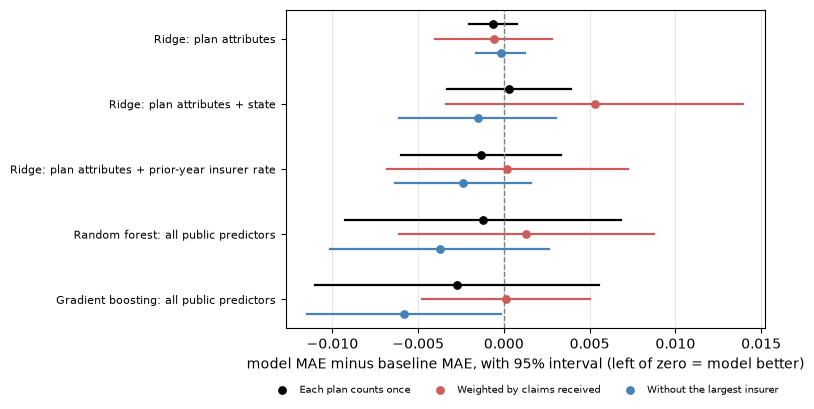

In [8]:
res_weighted = repeated_cv(d, weights=d["claims"].values)
res_nolargest = repeated_cv(d[d.iss != top])
settings = {"Each plan counts once": table3,
            "Weighted by claims received": paired_summary(res_weighted),
            "Without the largest insurer": paired_summary(res_nolargest)}
for name, t in settings.items():
    if name != "Each plan counts once":
        print(name); print(t.round(4).to_string()); print()

models = [m for m in table3.index if m != BASE]
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = {"Each plan counts once": "black", "Weighted by claims received": "indianred", "Without the largest insurer": "steelblue"}
for i, m in enumerate(models):
    for j, (name, t) in enumerate(settings.items()):
        yv = i + (j - 1) * 0.22
        ax.plot([t.loc[m, "95% low"], t.loc[m, "95% high"]], [yv, yv], color=colors[name], lw=1.6)
        ax.scatter(t.loc[m, "difference from baseline"], yv, color=colors[name], s=28, zorder=3, label=name if i == 0 else None)
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_yticks(range(len(models))); ax.set_yticklabels(models, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("model MAE minus baseline MAE, with 95% interval (left of zero = model better)")
ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "m2_fig2_paired_differences.png", dpi=200, bbox_inches="tight"); plt.show()

**What the model comparison shows.**

- **Random splits flatter every model.** Under random 5-fold splitting the random forest reaches an MAE of 0.0296 and gradient boosting 0.0305 against a baseline of 0.0495, which is 40.2% and 38.3% lower. In that design the tuning picks the most flexible setting in every fold (leaf size 5, 300 trees), because plans from the test insurers are also in the training data.
- **With whole insurers held out, no model is clearly better than the mean.** The baseline MAE is 0.0518. Plan attributes alone change it by -0.0006 (95% interval -0.0020 to +0.0008). Adding the insurer's prior-year rate gives -0.0013 (-0.0060 to +0.0033). The random forest gives -0.0012 (-0.0093 to +0.0069) and gradient boosting -0.0027 (-0.0110 to +0.0055). Every interval includes zero.
- **The Milestone 1 result for gradient boosting came from a model that was not tuned.** There, 300 trees with default settings were 1.6 points worse than the baseline. Tuned for unseen insurers, boosting chooses the smallest option (30 trees) in every fold and no longer does worse.
- **The split itself moves the answer.** The baseline MAE ranges from 0.0507 to 0.0537 across the ten repeats. That spread (0.0029) is larger than the average gain of any model in the same comparison (at most 0.0027), so a single 5-fold split could not have settled it.
- **Claim-volume weighting.** When each plan counts in proportion to its claims, the baseline MAE is 0.0368 and no model improves on it. The closest is ridge on plan attributes at -0.0006 (-0.0040 to +0.0028).
- **Insurer concentration.** Without the largest insurer, gradient boosting is 0.0058 better than the baseline and its interval just excludes zero (-0.0115 to -0.0001). It is the only one of the 15 comparisons to do so and it does not hold in the other two settings. I read it as weak evidence that an insurer's own history carries some signal, not as a reliable gain.

## 5. Absent from training, or new to the Marketplace?

Grouped cross-validation holds out insurers the model has not seen, but nearly all of them are established insurers with a public history. An insurer that is new to the Marketplace has none. The CMS flag separates the two cases: an insurer flagged new in one file has no claims in that file, and reports its first claims in the next one.

In [9]:
# Three situations that "an insurer the model has not seen" can mean
r = raw[2024]
ins = r.groupby("iss").agg(usable=("usable", "sum"), plans=("usable", "size"), new=(NEW, "first"), issuer_claims=(IREC + "_num", "max"))
print("Insurers in the 2024 file:", len(ins))
print("  with usable plans:", int((ins.usable > 0).sum()), "| of these, with a prior-year (2023) insurer rate:", int(d.groupby("iss")["prior_issuer_rate"].first().notna().sum()))
print("  flagged new to the Exchange:", int((ins.new == "Yes").sum()), f"({int(ins.loc[ins.new == 'Yes', 'plans'].sum())} plans);",
      "of these, with any insurer-level or plan-level claims:", int(((ins.new == "Yes") & ((ins.usable > 0) | ins.issuer_claims.notna())).sum()))
print("  established but with no usable plan:", int(((ins.new != "Yes") & (ins.usable == 0)).sum()),
      f"({int(ins.loc[(ins.new != 'Yes') & (ins.usable == 0), 'plans'].sum())} plans)")

def first_year_insurers(t):
    """Insurers with usable plans in claims year t that CMS flagged as new to the Exchange in the file for year t - 1."""
    flag = raw[t - 1].groupby("iss")[NEW].first()
    return [s for s in use[t]["iss"].unique() if flag.get(s) == "Yes"]

print()
for t in (2023, 2024):
    flag = raw[t - 1].groupby("iss")[NEW].first()
    fy = first_year_insurers(t)
    print(f"Flagged new in the {t - 1} file: {int((flag == 'Yes').sum())} insurers -> reporting usable claims for the first time in {t}: {len(fy)} insurers, "
          f"{int(use[t]['iss'].isin(fy).sum())} plans")

Insurers in the 2024 file: 185
  with usable plans: 149 | of these, with a prior-year (2023) insurer rate: 141
  flagged new to the Exchange: 26 (352 plans); of these, with any insurer-level or plan-level claims: 0
  established but with no usable plan: 10 (173 plans)

Flagged new in the 2022 file: 35 insurers -> reporting usable claims for the first time in 2023: 18 insurers, 115 plans
Flagged new in the 2023 file: 29 insurers -> reporting usable claims for the first time in 2024: 8 insurers, 55 plans


In [10]:
# Train on every usable plan of year t - 1, then predict year t for (a) first-year insurers and (b) all other insurers.
# No information from year t is used. First-year insurers have no history, so the models use plan type, metal level,
# exchange type and state only (enrollment is left out because its scale differs between files).
PREV = "Baseline: mean of the previous year's plan rates"
def temporal_test(t):
    tr, te = use[t - 1], use[t].copy()
    te["first_year"] = te["iss"].isin(first_year_insurers(t))
    out = pd.DataFrame({"year": t, "iss": te["iss"].values, "first_year": te["first_year"].values, "rate": te["rate"].values})
    out[PREV] = np.abs(te["rate"].values - tr["rate"].mean())
    for name, model in make_models(GroupKFold(4), cross_year=True).items():
        fit = model.fit(tr[FEATURES], tr["rate"].values, groups=tr["iss"].values)
        out[name] = np.abs(te["rate"].values - fit.predict(te[FEATURES]))
    return out
err = pd.concat([temporal_test(2023), temporal_test(2024)], ignore_index=True)
names = [c for c in err.columns if c not in ("year", "iss", "first_year", "rate")]

def cluster_ci(e, col):
    diff = e[col] - e[PREV]; key = e["iss"]                    # an insurer present in both years is one cluster
    s, n = diff.groupby(key).sum(), diff.groupby(key).size(); ids = s.index.values
    rng = np.random.default_rng(SEED)
    bs = [s[p].sum() / n[p].sum() for p in (rng.choice(ids, len(ids), replace=True) for _ in range(2000))]
    return diff.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

for label, mask in (("First-year insurers (new to the Marketplace)", err["first_year"]), ("All other insurers, one year ahead", ~err["first_year"])):
    e = err[mask]
    print(f"{label}: {e['iss'].nunique()} insurers, {len(e)} plans "
          f"(2023: {int((e.year == 2023).sum())}, 2024: {int((e.year == 2024).sum())})")
    rows = []
    for n in names:
        row = {"model": n, "MAE": e[n].mean()}
        if n != PREV:
            dm, lo, hi = cluster_ci(e, n); row.update({"difference from baseline": dm, "95% low": lo, "95% high": hi})
        rows.append(row)
    print(pd.DataFrame(rows).set_index("model").round(4).to_string()); print()

seen = pd.concat([use[t].loc[~use[t]["iss"].isin(first_year_insurers(t)), "iss"].isin(set(use[t - 1]["iss"])) for t in (2023, 2024)])
print(f"Share of the other insurers' plans whose insurer was already in the training year: {seen.mean():.3f}")
print(f"Baseline error for first-year insurers relative to other insurers: {err.loc[err.first_year, PREV].mean() / err.loc[~err.first_year, PREV].mean():.2f} times")
print()

# Do first-year insurers look like established ones? Compare insurer mean rates (each insurer counts once).
fy = err.groupby(["year", "iss", "first_year"])["rate"].mean().reset_index()
a, b = fy.loc[fy.first_year, "rate"], fy.loc[~fy.first_year, "rate"]
print(f"Insurer mean denial rate: first-year insurers mean {a.mean():.3f}, median {a.median():.3f}, SD {a.std():.3f} (n = {len(a)}) | "
      f"other insurers mean {b.mean():.3f}, median {b.median():.3f}, SD {b.std():.3f} (n = {len(b)} insurer-years)")
print(f"Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.3f}; Levene test for equal spread p = {stats.levene(a, b).pvalue:.4f}")
print(f"First-year insurers with a mean rate above 0.35: {int((a > 0.35).sum())} of {len(a)}; other insurer-years: {int((b > 0.35).sum())} of {len(b)}")

# Is the wider spread only small-sample noise? Compare claim volumes and repeat with larger plans.
vol = pd.concat([use[t].assign(year=t, first_year=use[t]["iss"].isin(first_year_insurers(t))) for t in (2023, 2024)])
print(f"Median claims received per plan: first-year insurers {vol.loc[vol.first_year, 'claims'].median():,.0f} | other insurers {vol.loc[~vol.first_year, 'claims'].median():,.0f}")
big = vol[vol["claims"] >= 1000].groupby(["year", "iss", "first_year"])["rate"].mean().reset_index()
print(f"Plans with at least 1,000 claims only: SD of insurer mean rates {big.loc[big.first_year, 'rate'].std():.3f} (n = {int(big.first_year.sum())}) "
      f"against {big.loc[~big.first_year, 'rate'].std():.3f} (n = {int((~big.first_year).sum())})")

First-year insurers (new to the Marketplace): 26 insurers, 170 plans (2023: 115, 2024: 55)


                                                     MAE  difference from baseline  95% low  95% high
model                                                                                                
Baseline: mean of the previous year's plan rates  0.0934                       NaN      NaN       NaN
Ridge: plan attributes                            0.0933                   -0.0001  -0.0014    0.0015
Ridge: plan attributes + state                    0.0930                   -0.0004  -0.0022    0.0016
Random forest: plan attributes + state            0.0956                    0.0022  -0.0019    0.0069
Gradient boosting: plan attributes + state        0.0962                    0.0028  -0.0044    0.0121

All other insurers, one year ahead: 172 insurers, 4763 plans (2023: 2291, 2024: 2472)


                                                     MAE  difference from baseline  95% low  95% high
model                                                                                                
Baseline: mean of the previous year's plan rates  0.0567                       NaN      NaN       NaN
Ridge: plan attributes                            0.0564                   -0.0003  -0.0008    0.0001
Ridge: plan attributes + state                    0.0552                   -0.0016  -0.0039    0.0004
Random forest: plan attributes + state            0.0544                   -0.0023  -0.0057    0.0003
Gradient boosting: plan attributes + state        0.0528                   -0.0039  -0.0082   -0.0007

Share of the other insurers' plans whose insurer was already in the training year: 0.996
Baseline error for first-year insurers relative to other insurers: 1.65 times

Insurer mean denial rate: first-year insurers mean 0.226, median 0.192, SD 0.132 (n = 26) | other insurers mean 0.183

In [11]:
# Insurers and plans with a history: how well does last year's rate predict this year's?
def pair(a, b):
    return use[a][["Plan_ID", "rate"]].merge(use[b][["Plan_ID", "rate", "iss"]], on="Plan_ID", suffixes=("_prev", "_cur"))
cal, test = pair(2022, 2023), pair(2023, 2024)
print(f"Plans usable in both 2022 and 2023: {len(cal)} | in both 2023 and 2024: {len(test)} of {len(d)} usable 2024 plans ({test['iss'].nunique()} insurers)")
print(f"Correlation of a plan's rate in consecutive years: 2022-23 {cal['rate_prev'].corr(cal['rate_cur']):.3f}, 2023-24 {test['rate_prev'].corr(test['rate_cur']):.3f}")

slope, intercept = np.polyfit(cal["rate_prev"], cal["rate_cur"], 1)                 # fitted on the earlier pair only
ins_prev = {cy: use[cy].groupby("iss").apply(lambda g: g[DEN + "_num"].sum() / g[REC + "_num"].sum(), include_groups=False) for cy in (2022, 2023)}
cal["ins_prev"] = cal["iss"].map(ins_prev[2022]); test["ins_prev"] = test["iss"].map(ins_prev[2023])
ok = cal["ins_prev"].notna(); s2, i2 = np.polyfit(cal.loc[ok, "ins_prev"], cal.loc[ok, "rate_cur"], 1)
print(f"Calibration fitted on 2022 to 2023: next rate = {intercept:.3f} + {slope:.3f} x plan's rate; = {i2:.3f} + {s2:.3f} x insurer's rate")

yt = test["rate_cur"].values; base = use[2023]["rate"].mean()
preds = {"Mean of 2023 plan rates (baseline)": np.full(len(test), base),
         "Plan's 2023 rate, unchanged": test["rate_prev"].values,
         "Insurer's 2023 rate, calibrated": (i2 + s2 * test["ins_prev"]).values,
         "Plan's 2023 rate, calibrated": intercept + slope * test["rate_prev"].values}
rng = np.random.default_rng(SEED); ids = test["iss"].unique(); rows = []
for name, p in preds.items():
    e = np.abs(yt - p); row = {"predictor": name, "MAE on 2024 rates": e.mean()}
    if "baseline" not in name:
        diff = pd.Series(e - np.abs(yt - base)); s, n = diff.groupby(test["iss"].values).sum(), diff.groupby(test["iss"].values).size()
        bs = [s[k].sum() / n[k].sum() for k in (rng.choice(ids, len(ids), replace=True) for _ in range(2000))]
        row.update({"difference from baseline": diff.mean(), "95% low": np.percentile(bs, 2.5), "95% high": np.percentile(bs, 97.5)})
    rows.append(row)
table5 = pd.DataFrame(rows).set_index("predictor")
print(table5.round(4).to_string())
print(f"Reduction in MAE from the calibrated plan rate: {1 - table5.iloc[3, 0] / table5.iloc[0, 0]:.3f}")

Plans usable in both 2022 and 2023: 1063 | in both 2023 and 2024: 1744 of 2527 usable 2024 plans (140 insurers)
Correlation of a plan's rate in consecutive years: 2022-23 0.547, 2023-24 0.565
Calibration fitted on 2022 to 2023: next rate = 0.084 + 0.579 x plan's rate; = 0.082 + 0.601 x insurer's rate


                                    MAE on 2024 rates  difference from baseline  95% low  95% high
predictor                                                                                         
Mean of 2023 plan rates (baseline)             0.0504                       NaN      NaN       NaN
Plan's 2023 rate, unchanged                    0.0537                    0.0033  -0.0103    0.0163
Insurer's 2023 rate, calibrated                0.0470                   -0.0034  -0.0135    0.0064
Plan's 2023 rate, calibrated                   0.0448                   -0.0056  -0.0160    0.0041
Reduction in MAE from the calibrated plan rate: 0.112


**What these tests show.** "An insurer the model has not seen" covers four situations.

| Situation | How it is tested | Result |
|---|---|---|
| Established insurer, absent from training | Section 4: 149 insurers, 141 of them with a prior-year rate | No model clearly better than the mean |
| Established insurer, one year ahead | Train on one year, predict the next: 172 insurers, 4,763 plans | Gradient boosting: 0.0528 against a baseline of 0.0567 (difference -0.0039, 95% interval -0.0082 to -0.0007) |
| Insurer in its first claims year | Same design: 26 insurers flagged new the year before, 170 plans | Baseline 0.0934; best model -0.0004 (-0.0022 to +0.0016) |
| Insurer flagged new, no claims yet | 26 insurers, 352 plans in the 2024 file | Cannot be evaluated until a later file |

- **New insurers are much harder to predict.** The baseline error for first-year insurers is 0.0934, 1.65 times the 0.0567 for other insurers, and no model reduces it. The reason is spread, not level. The standard deviation of insurer mean rates is 0.132 for first-year insurers against 0.067 for the others (Levene p = 0.0003), and 4 of 26 have a mean rate above 35% against 5 of 297. The medians are close (0.192 against 0.187; Mann-Whitney p = 0.216). This is not small-sample noise: counting only plans with at least 1,000 claims, the spread is 0.120 against 0.067.
- **What helps is knowing the insurer.** For the other insurers, 99.6% of plans belong to an insurer that was already in the training year. There, gradient boosting with state is 0.4 points better than the mean and its interval excludes zero, because state partly identifies the insurer and the model carries over what it learned about each one. For plans observed in both 2023 and 2024, the plan's own 2023 rate, pulled toward the mean by a calibration fitted on 2022 to 2023, lowers MAE from 0.0504 to 0.0448 (11.2%), although the interval (-0.0160 to +0.0041) still includes zero. Using the 2023 rate unchanged is worse than the mean (0.0537).
- **Consequence for the Milestone 1 wording.** The grouped cross-validation result supports a claim about established insurers left out of training. It does not support a claim about insurers new to the market. The first-year test addresses those directly, with only 26 insurers.

## 6. Summary and remaining work

**Findings.**

1. **Primary result.** About 61% of the variation in plan denial rates belongs to the insurer (95% interval 45% to 74%), and plan attributes explain under 4% of that insurer variation. The share stays above one half when the largest insurer is removed, when plans are weighted or filtered by claim volume, when the sample is reweighted for selection, and in the two earlier years.
2. **Selection.** Excluded plans are a different mix, but once they report they are not consistently higher or lower than their insurer's other plans.
3. **Prediction.** With whole insurers held out, no model is clearly better than predicting the mean. Random splitting would have suggested a 40% improvement.
4. **Absent is not new.** Insurers in their first claims year have errors 1.65 times larger, because their denial rates vary far more. Prediction improves only where the insurer itself is already known.

**What changed since Milestone 1.** All models are tuned the same way, so gradient boosting no longer looks worse than the baseline. The rule "beats the baseline by more than one standard deviation of five folds" is replaced by a paired interval over 50 folds. The claim about "unseen insurers" is narrowed to established insurers, and new insurers are tested separately.

**Remaining work for the final paper (Week 13).**

1. Write the paper with the variance decomposition as the main result and the prediction tests as its consequence.
2. Add bootstrap intervals to the sensitivity rows in Section 3.
3. Repeat the Section 4 comparison on the 2023 claims year.
4. State what consumers, regulators and hospital revenue-cycle teams can and cannot infer from the file.
5. Prepare the five-minute presentation.

**References**

Centers for Medicare & Medicaid Services. (2025). *Transparency in coverage public use files, plan years 2024, 2025 and 2026* [Data sets]. https://www.cms.gov/marketplace/resources/data/public-use-files

Field, C. A., & Welsh, A. H. (2007). Bootstrapping clustered data. *Journal of the Royal Statistical Society Series B: Statistical Methodology, 69*(3), 369–390. https://doi.org/10.1111/j.1467-9868.2007.00593.x

Nadeau, C., & Bengio, Y. (2003). Inference for the generalization error. *Machine Learning, 52*(3), 239–281. https://doi.org/10.1023/A:1024068626366

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

**AI use.** The code and text in this notebook were generated with Claude (Anthropic), building on my Milestone 1 analysis and the reviews from the instructor and two classmates.